In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Read the CSV file into a DataFrame
df = pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')
print(df.head())  # Display the first few rows of the DataFrame

   Person ID Gender  Age            Occupation  Sleep Duration  \
0          1   Male   27     Software Engineer             6.1   
1          2   Male   28                Doctor             6.2   
2          3   Male   28                Doctor             6.2   
3          4   Male   28  Sales Representative             5.9   
4          5   Male   28  Sales Representative             5.9   

   Quality of Sleep  Physical Activity Level  Stress Level BMI Category  \
0                 6                       42             6   Overweight   
1                 6                       60             8       Normal   
2                 6                       60             8       Normal   
3                 4                       30             8        Obese   
4                 4                       30             8        Obese   

  Blood Pressure  Heart Rate  Daily Steps Sleep Disorder  
0         126/83          77         4200            NaN  
1         125/80          75      

In [9]:
df = df.drop('Person ID', axis=1)  # Drop the 'Person ID' column

In [10]:
# Split text values ​​based on the forward slash '/'
df[['Systolic_BP', 'Diastolic_BP']] = df['Blood Pressure'].str.split('/', expand=True)

# Change the data type from a text string to an integer.
df['Systolic_BP'] = df['Systolic_BP'].astype(int)
df['Diastolic_BP'] = df['Diastolic_BP'].astype(int)

# Drop the old 'Blood Pressure' text column
df = df.drop('Blood Pressure', axis=1)

In [11]:
# Mengisi nilai kosong dengan teks 'None' (Tidak ada gangguan)
df['Sleep Disorder'] = df['Sleep Disorder'].fillna('None')

In [12]:
# Melihat ringkasan struktur DataFrame dan mengecek nilai null
print(df.info())

# Menampilkan data terbaru
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Gender                   374 non-null    object 
 1   Age                      374 non-null    int64  
 2   Occupation               374 non-null    object 
 3   Sleep Duration           374 non-null    float64
 4   Quality of Sleep         374 non-null    int64  
 5   Physical Activity Level  374 non-null    int64  
 6   Stress Level             374 non-null    int64  
 7   BMI Category             374 non-null    object 
 8   Heart Rate               374 non-null    int64  
 9   Daily Steps              374 non-null    int64  
 10  Sleep Disorder           374 non-null    object 
 11  Systolic_BP              374 non-null    int32  
 12  Diastolic_BP             374 non-null    int32  
dtypes: float64(1), int32(2), int64(6), object(4)
memory usage: 35.2+ KB
None


,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Sleep Disorder,Systolic_BP,Diastolic_BP
0,Male,27,Software Engineer,6.1,6,42,6,Overweight,77,4200,None,126,83
1,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,None,125,80
2,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,None,125,80
3,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90
4,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90


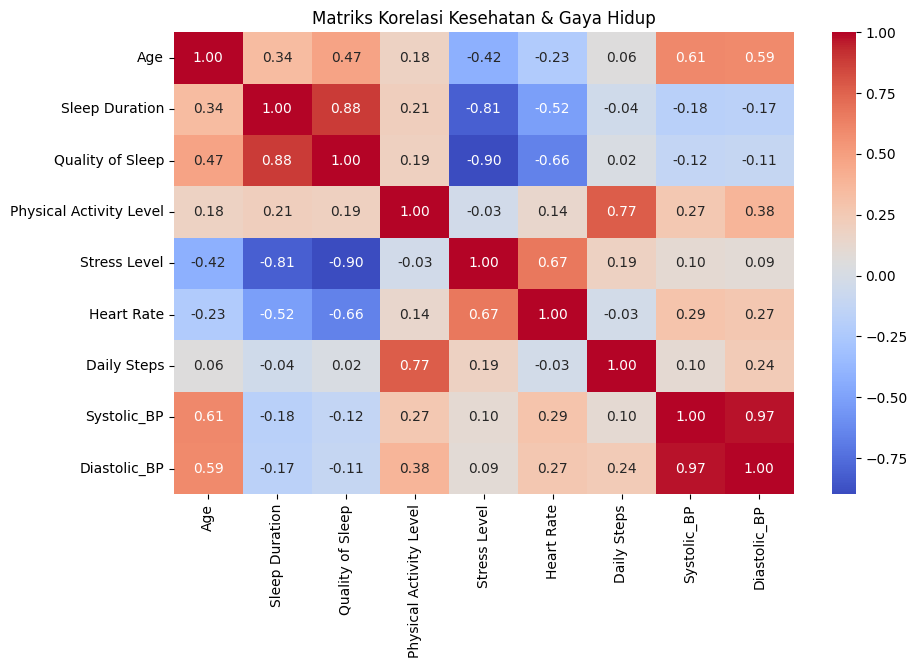

C:\Users\sagita pra kosa\AppData\Local\Temp\ipykernel_10580\1074364643.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Occupation', y='Stress Level', data=df, palette='viridis')


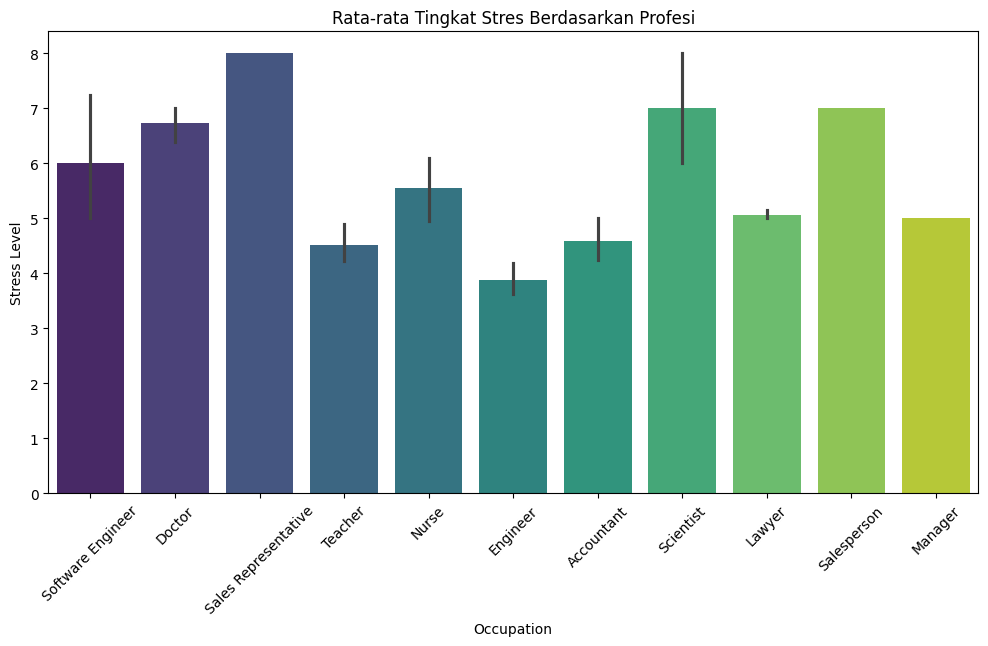

In [13]:
# Memisahkan kolom numerik untuk melihat korelasi
numeric_cols = df.select_dtypes(include=['int32', 'int64', 'float64']).columns

# Membuat Heatmap Korelasi
plt.figure(figsize=(10, 6))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Matriks Korelasi Kesehatan & Gaya Hidup")
plt.show()

# Visualisasi Tingkat Stres berdasarkan Profesi
plt.figure(figsize=(12, 6))
sns.barplot(x='Occupation', y='Stress Level', data=df, palette='viridis')
plt.xticks(rotation=45)
plt.title("Rata-rata Tingkat Stres Berdasarkan Profesi")
plt.show()

In [14]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
categorical_cols = ['Gender', 'Occupation', 'BMI Category', 'Sleep Disorder']

# Melakukan perulangan untuk mengubah setiap kolom teks menjadi angka
for col in categorical_cols:
    df[col] = le.fit_transform(df[col])

# Melihat hasil akhir data yang sudah sepenuhnya berbentuk angka
print(df.head())

   Gender  Age  Occupation  Sleep Duration  Quality of Sleep  \
0       1   27           9             6.1                 6   
1       1   28           1             6.2                 6   
2       1   28           1             6.2                 6   
3       1   28           6             5.9                 4   
4       1   28           6             5.9                 4   

   Physical Activity Level  Stress Level  BMI Category  Heart Rate  \
0                       42             6             3          77   
1                       60             8             0          75   
2                       60             8             0          75   
3                       30             8             2          85   
4                       30             8             2          85   

   Daily Steps  Sleep Disorder  Systolic_BP  Diastolic_BP  
0         4200               1          126            83  
1        10000               1          125            80  
2        10000

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Pisahkan kolom target (yang ingin ditebak) dan kolom fitur (data pendukung)
X = df.drop(['Stress Level'], axis=1) # Semua kolom kecuali Stress Level
y = df['Stress Level'] # Kolom Stress Level yang akan diprediksi

# 2. Bagi data: 80% untuk bahan belajar (Training), 20% untuk ujian (Testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Panggil "otak" Machine Learning-nya dan mulai proses belajar
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# 4. Beri soal ujian ke model berdasarkan data Testing yang belum pernah ia lihat
y_pred = rf_model.predict(X_test)

# 5. Cek nilai ujiannya (Akurasi)
print("Akurasi Model:", accuracy_score(y_test, y_pred))
print("\nLaporan Klasifikasi:\n", classification_report(y_test, y_pred))

Akurasi Model: 1.0

Laporan Klasifikasi:
               precision    recall  f1-score   support

           3       1.00      1.00      1.00        12
           4       1.00      1.00      1.00        10
           5       1.00      1.00      1.00        14
           6       1.00      1.00      1.00        10
           7       1.00      1.00      1.00        12
           8       1.00      1.00      1.00        17

    accuracy                           1.00        75
   macro avg       1.00      1.00      1.00        75
weighted avg       1.00      1.00      1.00        75



In [16]:
import joblib

# Menyimpan model Random Forest ke dalam file
joblib.dump(rf_model, 'model_prediksi_stres.pkl')

print("Model berhasil disimpan!")

Model berhasil disimpan!


In [17]:
import requests

# 1. Alamat loket API kamu
url = 'http://127.0.0.1:5000/predict'

# 2. Data kesehatan pegawai bohongan untuk dites (harus berupa angka karena sudah di-encode)
data_pegawai = {
    'Gender': 1,               # 1 untuk Male
    'Age': 28,                 
    'Occupation': 9,           # 9 untuk Software Engineer
    'Sleep Duration': 5.5,     # Tidur cuma 5.5 jam
    'Quality of Sleep': 4,     # Kualitas tidur buruk (skala 1-10)
    'Physical Activity Level': 30, 
    'BMI Category': 2,         
    'Heart Rate': 85,          
    'Daily Steps': 3000,       
    'Sleep Disorder': 2,       
    'Systolic_BP': 140,        
    'Diastolic_BP': 90         
}

# 3. Kirim data ke API menggunakan metode POST
response = requests.post(url, json=data_pegawai)

# 4. Lihat hasil tebakan dari API
print("Jawaban dari Server:", response.json())

Jawaban dari Server: {'prediksi_stres': 8}
